In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pyagrum as gum
import pyagrum.lib.notebook as gnb

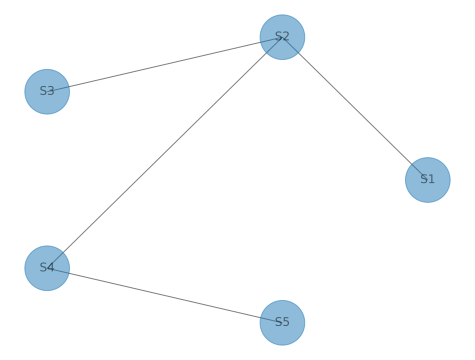

Neighbors of each station:
  N(S1) = ['S2']
  N(S2) = ['S1', 'S3', 'S4']
  N(S3) = ['S2']
  N(S4) = ['S2', 'S5']
  N(S5) = ['S4']

Number of nodes |V| = 5
Number of edges |E| = 4
Connected: True
Acyclic: True


In [9]:
# a)
stations = ["S1", "S2", "S3", "S4", "S5"]
edges = [("S1", "S2"), ("S2", "S3"), ("S2", "S4"), ("S4", "S5")]

# Graph, not DiGraph - no arrows here
graph = nx.Graph()
graph.add_nodes_from(stations)
graph.add_edges_from(edges)

# same drawing style as in the course
pos = nx.circular_layout(graph)
nx.draw(graph, with_labels=True, pos=pos, alpha=0.5, node_size=2000)
plt.show()

# who is directly connected to who
print("Neighbors of each station:")
for s in stations:
    print("  N(" + s + ") =", sorted(graph.neighbors(s)))

# connected + exactly n-1 edges = no edge left to close a cycle
print()
print("Number of nodes |V| =", graph.number_of_nodes())
print("Number of edges |E| =", graph.number_of_edges())
print("Connected:", nx.is_connected(graph))

# is_tree does exactly the two checks above
print("Acyclic:", nx.is_tree(graph))

In [10]:
# b)

states = ["Sunny", "Rainy", "Cloudy"]

# same prior for every station, from the assignment
p = {"Sunny": 0.5, "Rainy": 0.3, "Cloudy": 0.2}

# Psi is not symmetric, so I fix the convention: first key = first station of the edge
Psi = {
    "Sunny":  {"Sunny": 0.7, "Rainy": 0.2, "Cloudy": 0.1},
    "Rainy":  {"Sunny": 0.2, "Rainy": 0.6, "Cloudy": 0.2},
    "Cloudy": {"Sunny": 0.1, "Rainy": 0.3, "Cloudy": 0.6},
}

mrf = gum.MarkovRandomField()
for s in stations:
    mrf.add(gum.LabelizedVariable(s, "", states))

# one unary factor per station: phi_i(s) = p_i(s)
for s in stations:
    mrf.addFactor([s])
    for v in states:
        mrf.factor({s})[{s: v}] = p[v]

# one pairwise factor per edge: phi_ij(si, sj) = Psi[si][sj]
# filling cell by cell with a dict, so the ordering can't get mixed up
for i, j in edges:
    mrf.addFactor([i, j])
    for vi in states:
        for vj in states:
            mrf.factor({i, j})[{i: vi, j: vj}] = Psi[vi][vj]

print()
print(mrf)
print()
print("Unary factor on S1:")
print(mrf.factor({"S1"}))
print("Pairwise factor on the edge (S1, S2):")
print(mrf.factor({"S1", "S2"}))


MRF{nodes: 5, edges: 4, domainSize: 243, dim: 51}

Unary factor on S1:

  S1                         │
Sunny    │Rainy    │Cloudy   │
─────────│─────────│─────────│
 0.5000  │ 0.3000  │ 0.2000  │

Pairwise factor on the edge (S1, S2):

      ║  S1                         │
S2    ║Sunny    │Rainy    │Cloudy   │
──────║─────────│─────────│─────────│
Sunny ║ 0.7000  │ 0.2000  │ 0.1000  │
Rainy ║ 0.2000  │ 0.6000  │ 0.3000  │
Cloudy║ 0.1000  │ 0.2000  │ 0.6000  │



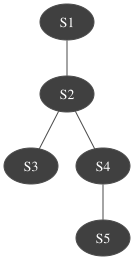

In [11]:
# c)

mrf.setProperty("name", "Weather network")
gnb.showMRF(mrf, view="graph")

In [12]:
# d)

from pyagrum.markov_random_field import ShaferShenoyMRFInference

# we assume the weather is known at the two ends of the tree
evidence = {"S1": "Rainy", "S5": "Cloudy"}
target = "S3"

ie = ShaferShenoyMRFInference(mrf)
ie.setEvidence(evidence)
ie.makeInference()

# posterior() sums out every other unobserved station for us
posterior = ie.posterior(target)

print("Evidence:", evidence)
print("Marginal distribution at", target + ":")
print(posterior)

# argmax of the marginal = marginal MAP at this single station
best = posterior.argmax()
print("Marginal MAP at", target + ":", states[best[0][0][target]],
      "with probability", round(best[1], 4))

Evidence: {'S1': 'Rainy', 'S5': 'Cloudy'}
Marginal distribution at S3:

  S3                         │
Sunny    │Rainy    │Cloudy   │
─────────│─────────│─────────│
 0.4651  │ 0.3922  │ 0.1426  │

Marginal MAP at S3: Sunny with probability 0.4651


In [14]:
# e)

unobserved = ["S2", "S3", "S4"]

ie_joint = ShaferShenoyMRFInference(mrf)
ie_joint.setEvidence(evidence)
ie_joint.addJointTarget(set(unobserved))
ie_joint.makeInference()

# the posterior over the three stations together, not one at a time
joint = ie_joint.jointPosterior(set(unobserved))

# argmax over the whole configuration
amax = joint.argmax()
joint_map = {s: states[amax[0][0][s]] for s in unobserved}

# for comparison: best state at each station taken separately
marginal_map = {s: states[ie_joint.posterior(s).argmax()[0][0][s]] for s in unobserved}

print()
print("Evidence:", evidence)
print("Joint MAP configuration:      ", joint_map, " P =", round(amax[1], 4))
print("Marginal maxima taken one by one:", marginal_map,
      " P =", round(joint[marginal_map], 4))
print("Do they coincide? : ", joint_map == marginal_map)


Evidence: {'S1': 'Rainy', 'S5': 'Cloudy'}
Joint MAP configuration:       {'S2': 'Sunny', 'S3': 'Sunny', 'S4': 'Sunny'}  P = 0.1621
Marginal maxima taken one by one: {'S2': 'Rainy', 'S3': 'Sunny', 'S4': 'Rainy'}  P = 0.0857
Do they coincide? :  False
